Acurácia do Modelo: 99.83%

Relatório de Classificação:
               precision    recall  f1-score   support

CARTÃO MESTRE       1.00      0.60      0.75         5
  NÃO PAGANTE       0.99      1.00      1.00      2783
      PAGANTE       1.00      1.00      1.00      7111

     accuracy                           1.00      9899
    macro avg       1.00      0.87      0.92      9899
 weighted avg       1.00      1.00      1.00      9899



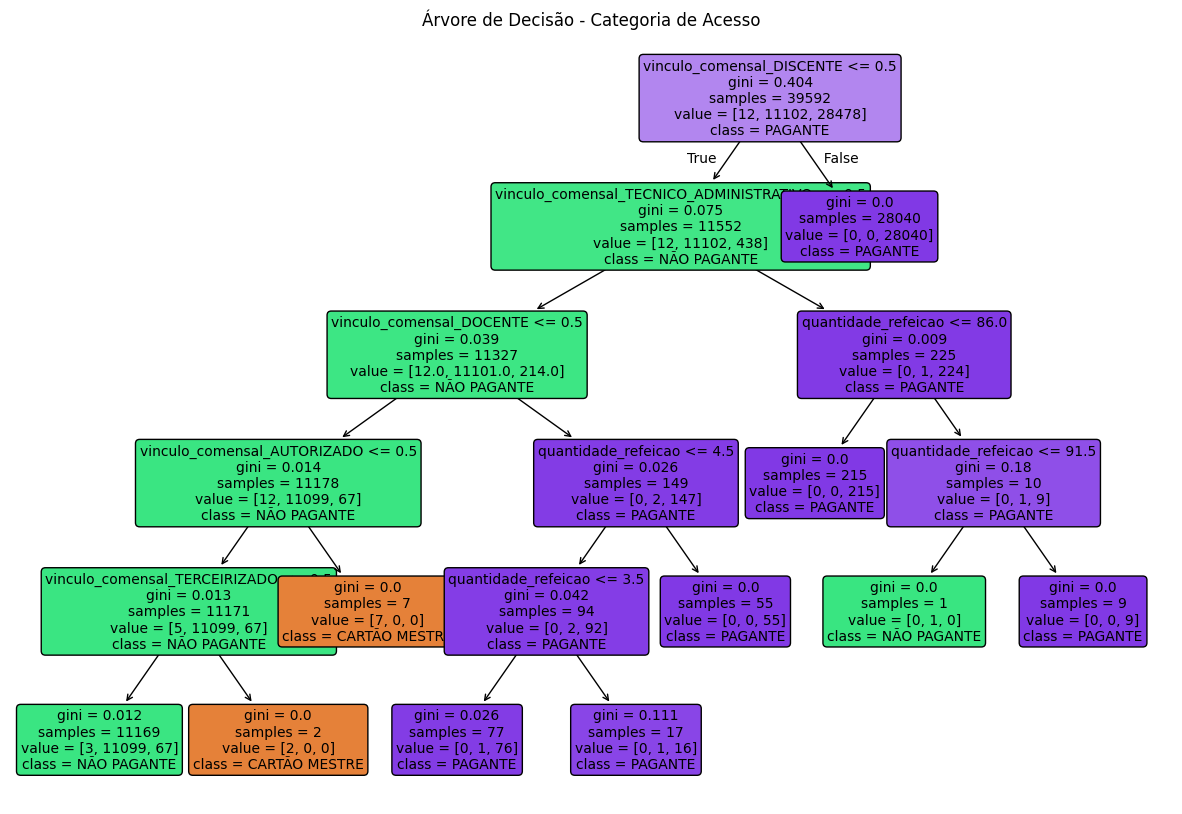

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

# 1. Carregar o dataset usando a URL raw do GitHub
df = pd.read_csv('https://raw.githubusercontent.com/bhpp12/datasets/main/17_prae_comensais_2024.csv')

# 2. Limpeza dos dados (Tratando outliers)
# há registros atípicos com mais de 48 mil refeições.
# Vamos filtrar para manter apenas o fluxo de usuários comuns.
df = df[df['quantidade_refeicao'] < 1000]

# 3. Definir as Features (X) e o Rótulo/Target (y)
# X (O que usamos para prever) / y (O que queremos adivinhar)
X = df[['vinculo_comensal', 'tipo_refeicao', 'quantidade_refeicao']]
y = df['categoria_acesso']

# 4. Pré-processamento: Converter variáveis categóricas em numéricas (One-Hot Encoding)
X = pd.get_dummies(X, columns=['vinculo_comensal', 'tipo_refeicao'])

# 5. Dividir os dados em Treino (80%) e Teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. Criar e Treinar o modelo de Árvore de Decisão
# max_depth=5 evita que a árvore fique gigantesca e sofra de "overfitting" (decore os dados)
modelo_arvore = DecisionTreeClassifier(max_depth=5, random_state=42)
modelo_arvore.fit(X_train, y_train)

# 7. Realizar as previsões usando os dados de teste separados
previsoes = modelo_arvore.predict(X_test)

# 8. Avaliar os resultados do modelo
acuracia = accuracy_score(y_test, previsoes)
print(f"Acurácia do Modelo: {acuracia * 100:.2f}%\n")

print("Relatório de Classificação:")
print(classification_report(y_test, previsoes, zero_division=0))

# 9. (Bônus) Visualizar a Árvore de Decisão Graficamente
plt.figure(figsize=(15, 10))
plot_tree(modelo_arvore,
          feature_names=X.columns,
          class_names=modelo_arvore.classes_,
          filled=True,
          rounded=True,
          fontsize=10)
plt.title("Árvore de Decisão - Categoria de Acesso")
plt.show()